In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.inspection import permutation_importance

In [ ]:
path='https://drive.google.com/uc?export=download&id=1chfJAFNJBCTpOhEDzwFMHf83oqEScUX-'
data_hp_usage=pd.read_csv(path)
data_hp_usage

,transaction_id,user_id,age,gender,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,stress_level,academic_work_impact,addiction_level,addicted_label
0,TXN00001,U00001,21,Male,3.23,2.01,0.89,4.55,7.55,248,154,3.95,Medium,Yes,NaN,0
1,TXN00002,U00002,24,Other,5.09,3.81,2.24,4.44,7.66,127,71,6.71,Medium,Yes,NaN,0
2,TXN00003,U00003,31,Other,6.06,1.36,3.83,2.35,4.92,44,106,8.68,High,No,Mild,0
3,TXN00004,U00004,32,Other,7.83,5.85,1.51,3.54,8.23,178,107,9.77,High,Yes,Moderate,1
4,TXN00005,U00005,25,Male,9.96,5.92,3.42,5.27,6.21,136,177,12.55,Low,No,Severe,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7495,TXN07496,U07496,26,Other,9.85,1.75,3.13,3.49,5.81,249,122,11.99,Low,Yes,Moderate,1
7496,TXN07497,U07497,35,Male,5.67,2.33,2.76,5.90,8.47,197,56,7.08,Low,No,NaN,0
7497,TXN07498,U07498,22,Female,9.99,3.61,1.09,1.16,8.17,207,24,12.84,Medium,Yes,Severe,1
7498,TXN07499,U07499,23,Male,8.74,1.59,0.07,4.64,6.19,134,62,10.52,High,Yes,Severe,1


In [ ]:
data_hp_usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   transaction_id           7500 non-null   object 
 1   user_id                  7500 non-null   object 
 2   age                      7500 non-null   int64  
 3   gender                   7500 non-null   object 
 4   daily_screen_time_hours  7500 non-null   float64
 5   social_media_hours       7500 non-null   float64
 6   gaming_hours             7500 non-null   float64
 7   work_study_hours         7500 non-null   float64
 8   sleep_hours              7500 non-null   float64
 9   notifications_per_day    7500 non-null   int64  
 10  app_opens_per_day        7500 non-null   int64  
 11  weekend_screen_time      7500 non-null   float64
 12  stress_level             7500 non-null   object 
 13  academic_work_impact     7500 non-null   object 
 14  addiction_level         

In [ ]:
data_hp_usage.isnull().sum()

,0
transaction_id,0
user_id,0
age,0
gender,0
daily_screen_time_hours,0
social_media_hours,0
gaming_hours,0
work_study_hours,0
sleep_hours,0
notifications_per_day,0


PRE PROCESSING

In [ ]:
#DROP KOLOM
kolom_di_drop = ['transaction_id', 'user_id', 'addicted_label','weekend_screen_time']
data_hp_usage_clean= data_hp_usage.drop(kolom_di_drop, axis=1)
data_hp_usage_clean

,age,gender,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,stress_level,academic_work_impact,addiction_level
0,21,Male,3.23,2.01,0.89,4.55,7.55,248,154,Medium,Yes,NaN
1,24,Other,5.09,3.81,2.24,4.44,7.66,127,71,Medium,Yes,NaN
2,31,Other,6.06,1.36,3.83,2.35,4.92,44,106,High,No,Mild
3,32,Other,7.83,5.85,1.51,3.54,8.23,178,107,High,Yes,Moderate
4,25,Male,9.96,5.92,3.42,5.27,6.21,136,177,Low,No,Severe
...,...,...,...,...,...,...,...,...,...,...,...,...
7495,26,Other,9.85,1.75,3.13,3.49,5.81,249,122,Low,Yes,Moderate
7496,35,Male,5.67,2.33,2.76,5.90,8.47,197,56,Low,No,NaN
7497,22,Female,9.99,3.61,1.09,1.16,8.17,207,24,Medium,Yes,Severe
7498,23,Male,8.74,1.59,0.07,4.64,6.19,134,62,High,Yes,Severe


In [ ]:
#Handle Missing Value
data_hp_usage_clean['addiction_level']=data_hp_usage_clean['addiction_level'].fillna('None')
data_hp_usage_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      7500 non-null   int64  
 1   gender                   7500 non-null   object 
 2   daily_screen_time_hours  7500 non-null   float64
 3   social_media_hours       7500 non-null   float64
 4   gaming_hours             7500 non-null   float64
 5   work_study_hours         7500 non-null   float64
 6   sleep_hours              7500 non-null   float64
 7   notifications_per_day    7500 non-null   int64  
 8   app_opens_per_day        7500 non-null   int64  
 9   stress_level             7500 non-null   object 
 10  academic_work_impact     7500 non-null   object 
 11  addiction_level          7500 non-null   object 
dtypes: float64(5), int64(3), object(4)
memory usage: 703.3+ KB


In [ ]:
data_hp_usage_clean.isnull().sum()

,0
age,0
gender,0
daily_screen_time_hours,0
social_media_hours,0
gaming_hours,0
work_study_hours,0
sleep_hours,0
notifications_per_day,0
app_opens_per_day,0
stress_level,0


In [ ]:
data_hp_usage_clean.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
7495,False
7496,False
7497,False
7498,False


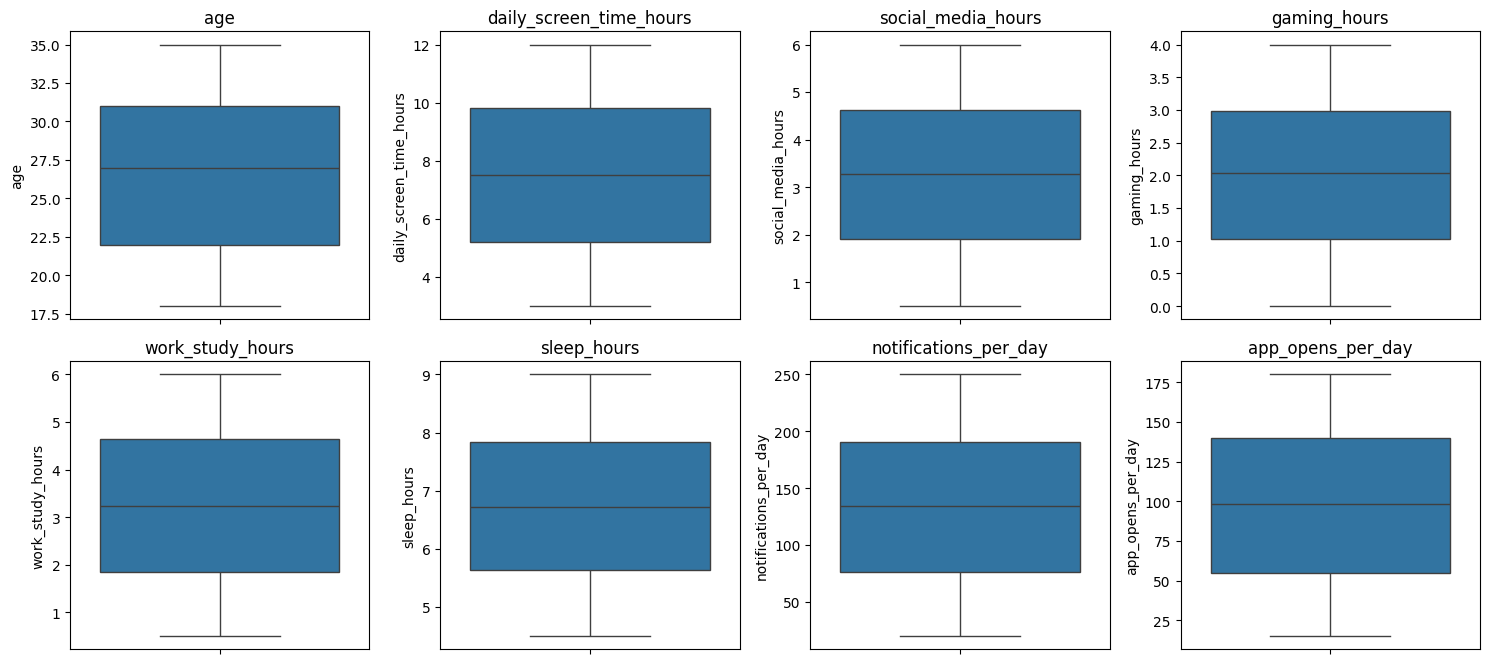

In [ ]:
#CEK OUTLIER + BOXPLOT
kolom_numerik = data_hp_usage_clean.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(15, 10))
for i, col in enumerate(kolom_numerik, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(y=data_hp_usage_clean[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [ ]:
#ENCODING
#1. Ordinal Encoding
mapping_target = {'None': 0, 'Mild': 1, 'Moderate': 2, 'Severe': 3}
data_hp_usage_clean['addiction_level'] = data_hp_usage_clean['addiction_level'].map(mapping_target)

mapping_stress = {'Low': 0, 'Medium': 1, 'High': 2}
data_hp_usage_clean['stress_level'] = data_hp_usage_clean['stress_level'].map(mapping_stress)

In [ ]:
#2. Encoding Kolom Kategorikal
mapping_gender = {'Male': 0, 'Female': 1, 'Other': 2}
data_hp_usage_clean['gender'] = data_hp_usage_clean['gender'].map(mapping_gender)

mapping_impact = {'No': 0, 'Yes': 1}
data_hp_usage_clean['academic_work_impact'] = data_hp_usage_clean['academic_work_impact'].map(mapping_impact)

In [ ]:
data_hp_usage_clean

,age,gender,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,stress_level,academic_work_impact,addiction_level
0,21,0,3.23,2.01,0.89,4.55,7.55,248,154,1,1,0
1,24,2,5.09,3.81,2.24,4.44,7.66,127,71,1,1,0
2,31,2,6.06,1.36,3.83,2.35,4.92,44,106,2,0,1
3,32,2,7.83,5.85,1.51,3.54,8.23,178,107,2,1,2
4,25,0,9.96,5.92,3.42,5.27,6.21,136,177,0,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...
7495,26,2,9.85,1.75,3.13,3.49,5.81,249,122,0,1,2
7496,35,0,5.67,2.33,2.76,5.90,8.47,197,56,0,0,0
7497,22,1,9.99,3.61,1.09,1.16,8.17,207,24,1,1,3
7498,23,0,8.74,1.59,0.07,4.64,6.19,134,62,2,1,3


In [ ]:
data_hp_usage_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      7500 non-null   int64  
 1   gender                   7500 non-null   int64  
 2   daily_screen_time_hours  7500 non-null   float64
 3   social_media_hours       7500 non-null   float64
 4   gaming_hours             7500 non-null   float64
 5   work_study_hours         7500 non-null   float64
 6   sleep_hours              7500 non-null   float64
 7   notifications_per_day    7500 non-null   int64  
 8   app_opens_per_day        7500 non-null   int64  
 9   stress_level             7500 non-null   int64  
 10  academic_work_impact     7500 non-null   int64  
 11  addiction_level          7500 non-null   int64  
dtypes: float64(5), int64(7)
memory usage: 703.3 KB


In [ ]:
data_hp_usage_clean.describe()

,age,gender,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,stress_level,academic_work_impact,addiction_level
count,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000
mean,26.568800,0.991067,7.499912,3.273484,2.014183,3.242420,6.737561,134.257333,97.832400,1.007600,0.499600,1.923067
std,5.197108,0.819681,2.609188,1.585342,1.146039,1.600765,1.283605,66.586883,48.423349,0.821644,0.500033,0.968817
min,18.000000,0.000000,3.000000,0.500000,0.000000,0.500000,4.500000,20.000000,15.000000,0.000000,0.000000,0.000000
25%,22.000000,0.000000,5.220000,1.910000,1.020000,1.850000,5.630000,76.000000,55.000000,0.000000,0.000000,1.000000
50%,27.000000,1.000000,7.525000,3.270000,2.040000,3.230000,6.720000,134.000000,98.000000,1.000000,0.000000,2.000000
75%,31.000000,2.000000,9.810000,4.630000,2.990000,4.640000,7.840000,191.000000,140.000000,2.000000,1.000000,3.000000
max,35.000000,2.000000,12.000000,6.000000,4.000000,6.000000,9.000000,250.000000,180.000000,2.000000,1.000000,3.000000


ANALYSIS DATA EXPLORATORY

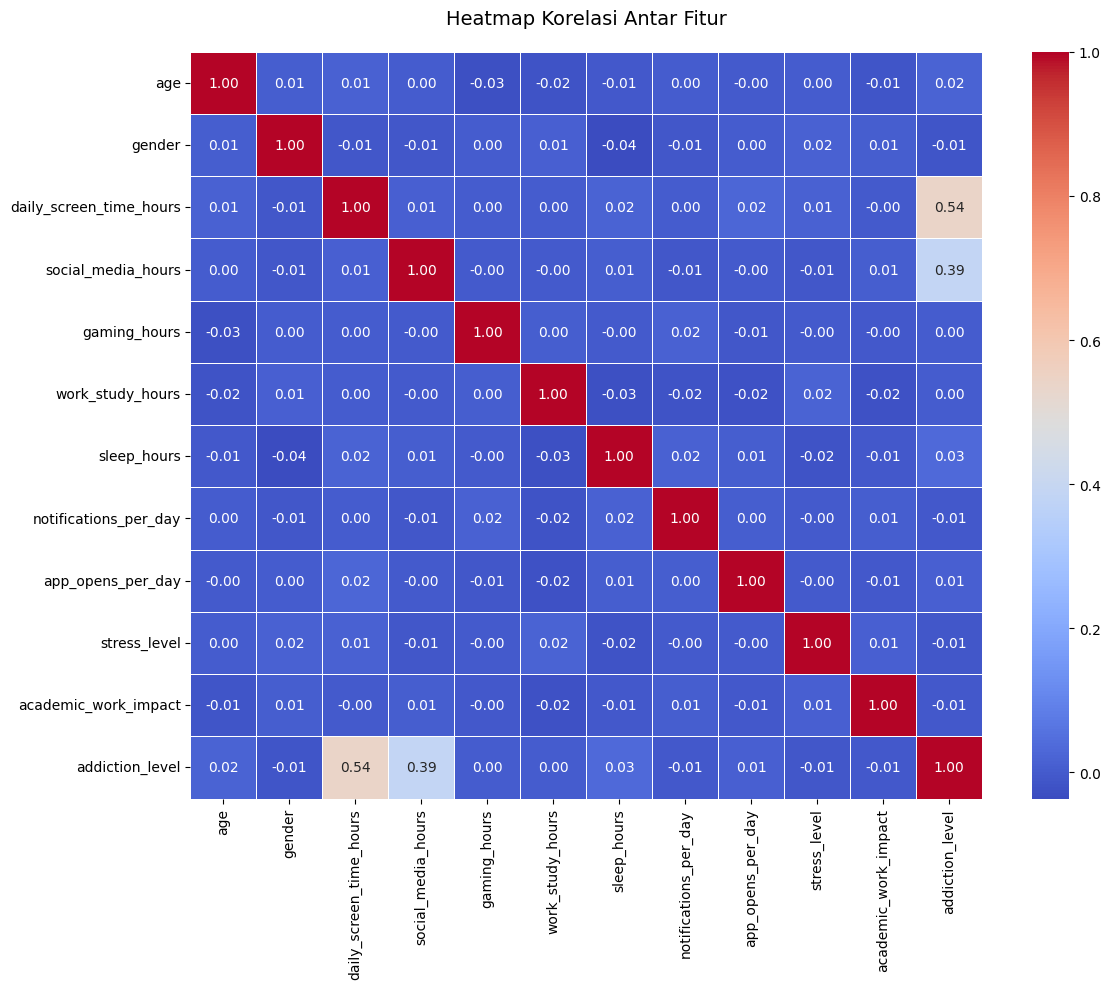

In [ ]:
#HEATMAP KORELASI
matriks_korelasi = data_hp_usage_clean.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(matriks_korelasi,
            annot=True,
            fmt=".2f",
            cmap='coolwarm',
            linewidths=0.5,
            cbar=True)

plt.title("Heatmap Korelasi Antar Fitur", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

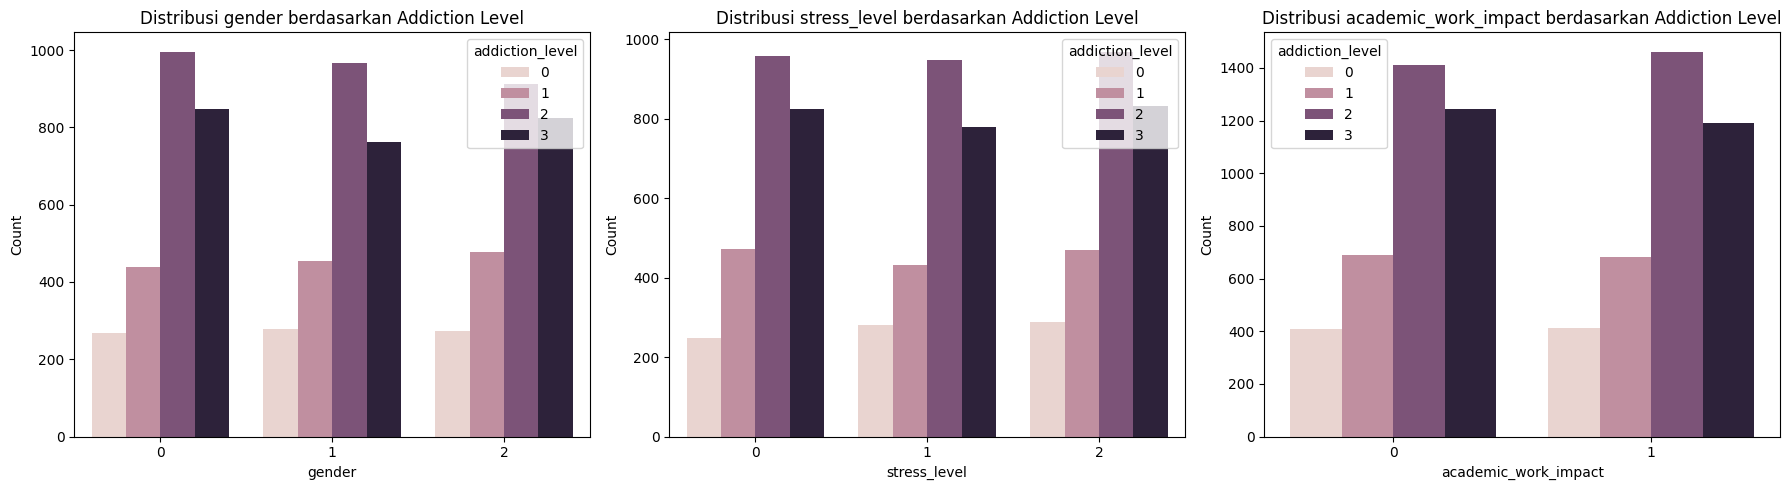

In [ ]:
fitur_kategori = ['gender', 'stress_level', 'academic_work_impact']

plt.figure(figsize=(18, 5))
for i, col in enumerate(fitur_kategori, 1):
    plt.subplot(1, 3, i)
    sns.countplot(data=data_hp_usage_clean, x=col, hue='addiction_level',
                  hue_order=['None', 'Mild', 'Moderate', 'Severe'])
    plt.title(f"Distribusi {col} berdasarkan Addiction Level")
    plt.ylabel("Count")
plt.tight_layout()
plt.show()

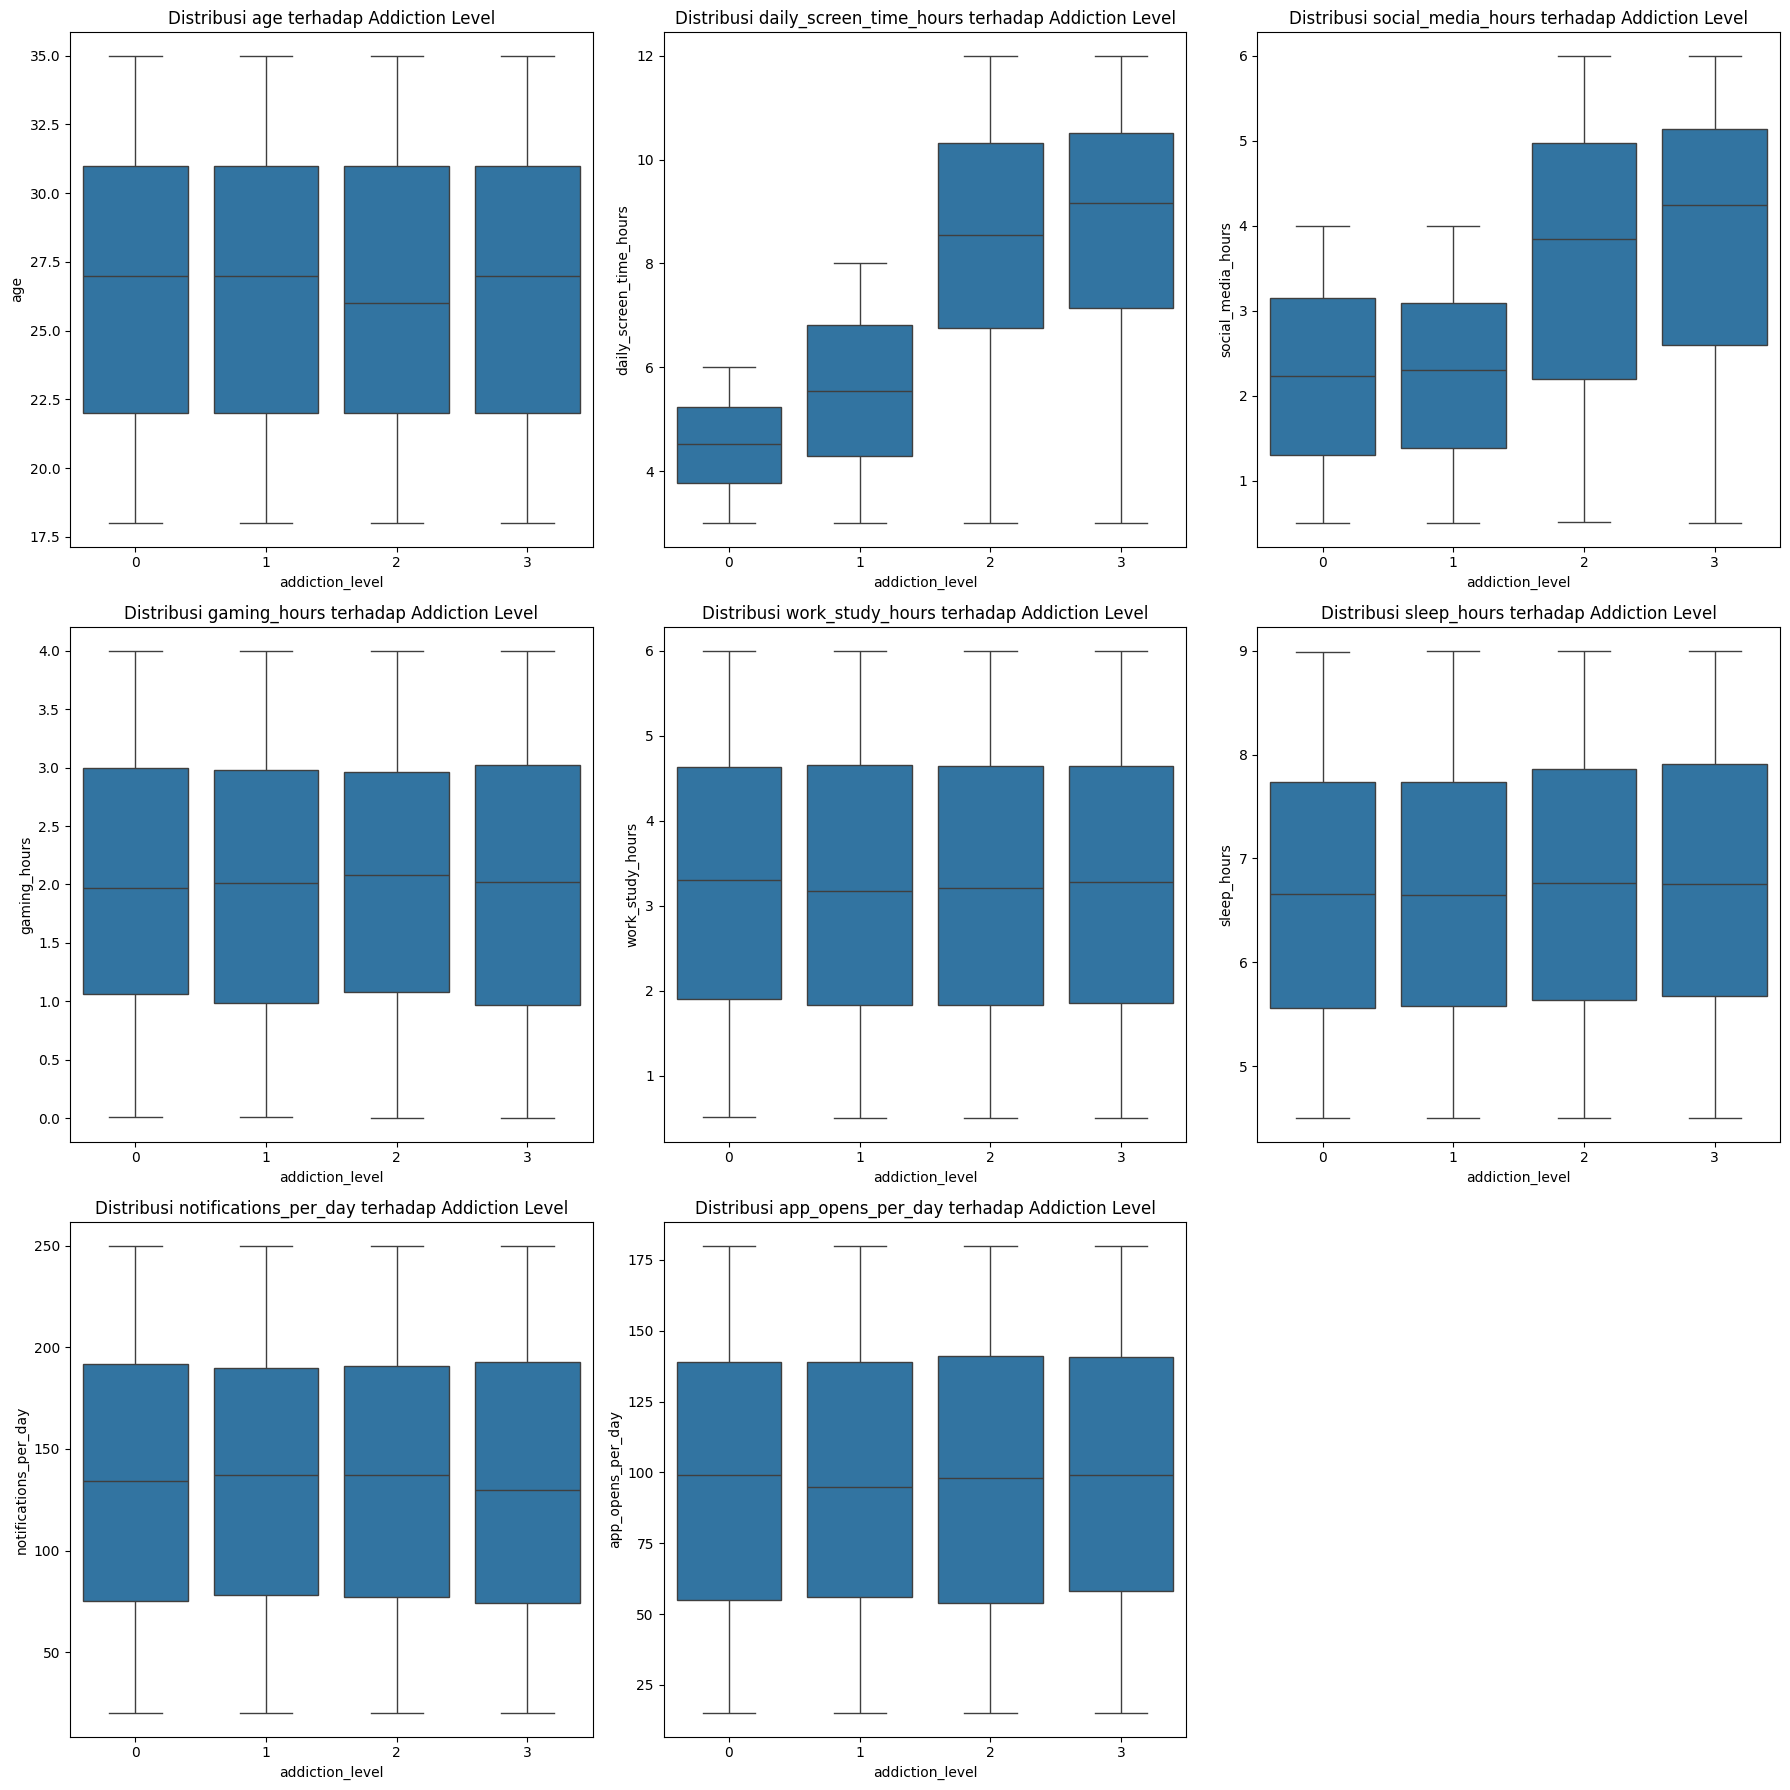

In [ ]:
fitur_numerik = [
    'age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours',
    'work_study_hours', 'sleep_hours', 'notifications_per_day',
    'app_opens_per_day'
]

plt.figure(figsize=(18, 18))
for i, col in enumerate(fitur_numerik, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(data=data_hp_usage_clean, x='addiction_level', y=col,
                order=[0, 1, 2, 3])
    plt.title(f"Distribusi {col} terhadap Addiction Level")
plt.tight_layout()
plt.show()

/tmp/ipykernel_2790/2111213622.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data_hp_usage_clean, x='addiction_level', palette='viridis')


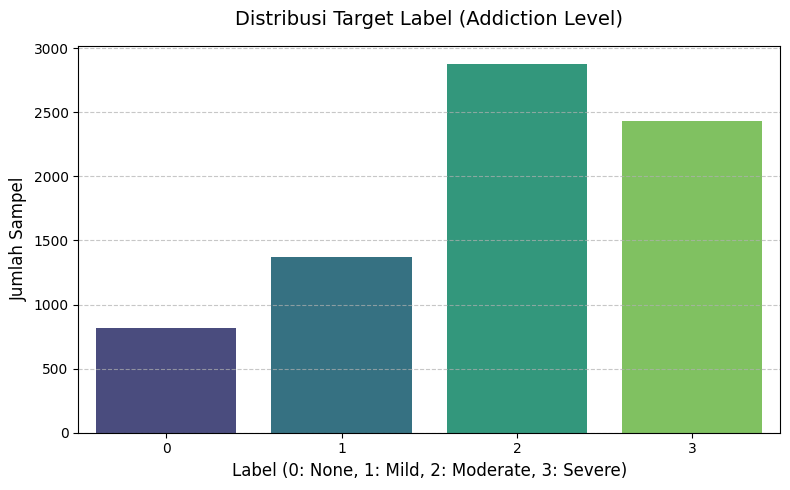

In [ ]:
#VISUALISASI DISTRIBUSI LABEL
plt.figure(figsize=(8, 5))
sns.countplot(data=data_hp_usage_clean, x='addiction_level', palette='viridis')

plt.title('Distribusi Target Label (Addiction Level)', fontsize=14, pad=15)
plt.xlabel('Label (0: None, 1: Mild, 2: Moderate, 3: Severe)', fontsize=12)
plt.ylabel('Jumlah Sampel', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

SPLIT DATA TRAIN & TEST (SESUDAH DAN SEBELUM SMOTE)

In [ ]:
X = data_hp_usage_clean.drop(columns=['addiction_level'])
y = data_hp_usage_clean['addiction_level']

X_train_imb, X_test, y_train_imb, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#SMOTE
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_imb, y_train_imb)

# STANDARISASI
scaler = StandardScaler()

# STANDARISASI IMBALANCED
X_train_imb_scaled = scaler.fit_transform(X_train_imb)

# STANDARISASI BALANCED
X_train_bal_scaled = scaler.fit_transform(X_train_bal)

# STANDARISASI DATA TEST
X_test_scaled = scaler.transform(X_test)

print("DISTRIBUSI SEBELUM SMOTE")
print(y_train_imb.value_counts().sort_index())

print("DISTRIBUSI SESUDAH SMOTE (Balanced)")
print(y_train_bal.value_counts().sort_index())

DISTRIBUSI SEBELUM SMOTE
addiction_level
0     655
1    1099
2    2299
3    1947
Name: count, dtype: int64
DISTRIBUSI SESUDAH SMOTE (Balanced)
addiction_level
0    2299
1    2299
2    2299
3    2299
Name: count, dtype: int64


MODEL KNN DAN RANDOM FOREST

In [ ]:
#Fungsi Visualisasi Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['None', 'Mild', 'Moderate', 'Severe'],
                yticklabels=['None', 'Mild', 'Moderate', 'Severe'])
    plt.title(title, fontsize=12, pad=10)
    plt.xlabel('Prediksi Model')
    plt.ylabel('Label Sebenarnya')
    plt.tight_layout()
    plt.show()

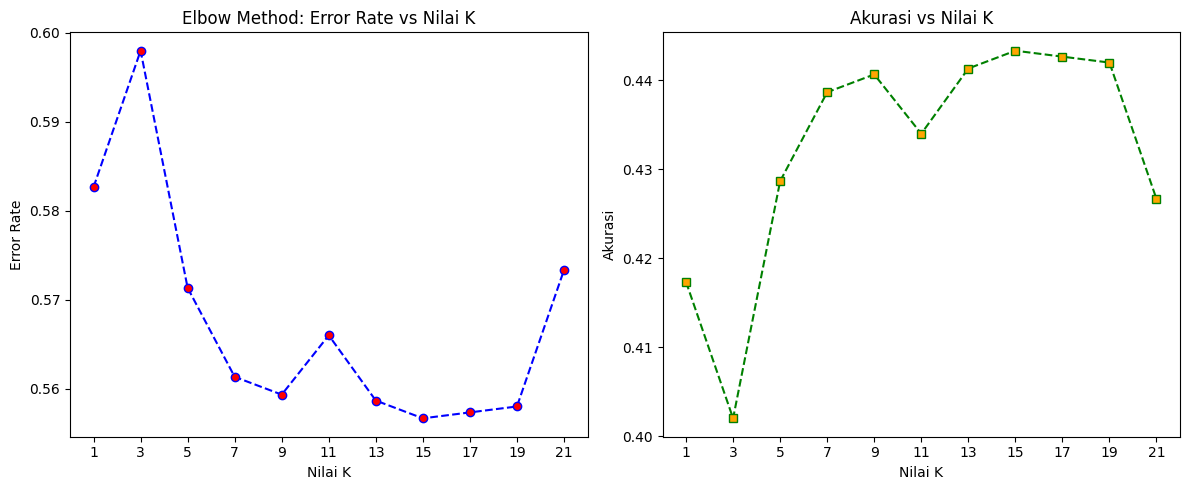

Berdasarkan grafik, Nilai K paling optimal adalah: K = 15
Akurasi tertinggi yang dicapai pada tahap pencarian: 44.33%



In [ ]:
error_rate = []
akurasi_list = []
k_range = range(1, 22, 2)

for k in k_range:
    knn_test = KNeighborsClassifier(n_neighbors=k)
    knn_test.fit(X_train_bal_scaled, y_train_bal)
    pred_k = knn_test.predict(X_test_scaled)
    error_rate.append(np.mean(pred_k != y_test))
    akurasi_list.append(accuracy_score(y_test, pred_k))

# Visualisasi Elbow Method
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(k_range, error_rate, color='blue', linestyle='dashed', marker='o', markerfacecolor='red')
plt.title('Elbow Method: Error Rate vs Nilai K')
plt.xlabel('Nilai K')
plt.ylabel('Error Rate')
plt.xticks(k_range)

plt.subplot(1, 2, 2)
plt.plot(k_range, akurasi_list, color='green', linestyle='dashed', marker='s', markerfacecolor='orange')
plt.title('Akurasi vs Nilai K')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.xticks(k_range)
plt.tight_layout()
plt.show()

k_optimal = k_range[np.argmax(akurasi_list)]
print(f"Berdasarkan grafik, Nilai K paling optimal adalah: K = {k_optimal}")
print(f"Akurasi tertinggi yang dicapai pada tahap pencarian: {max(akurasi_list):.2%}\n")

Akurasi Keseluruhan: 45.93%

Classification Report:
              precision    recall  f1-score   support

        None       0.47      0.20      0.28       164
        Mild       0.49      0.43      0.46       274
    Moderate       0.45      0.58      0.51       575
      Severe       0.46      0.42      0.44       487

    accuracy                           0.46      1500
   macro avg       0.47      0.41      0.42      1500
weighted avg       0.46      0.46      0.45      1500



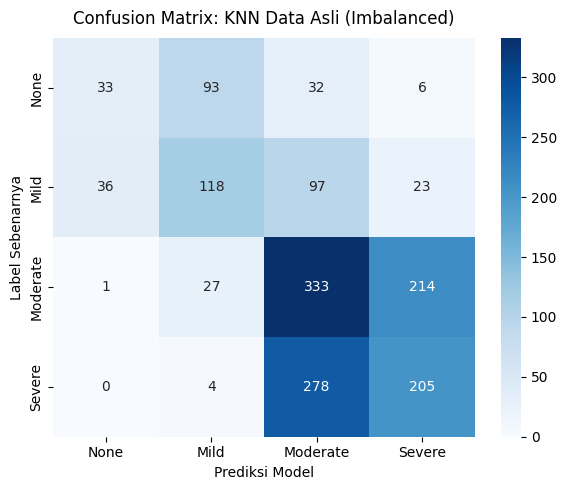

In [ ]:
#MODEL KNN DATA ASLI
knn_imb = KNeighborsClassifier(n_neighbors=k_optimal)
knn_imb.fit(X_train_imb_scaled, y_train_imb)
y_pred_knn_imb = knn_imb.predict(X_test_scaled)

print(f"Akurasi Keseluruhan: {accuracy_score(y_test, y_pred_knn_imb):.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_knn_imb, target_names=['None', 'Mild', 'Moderate', 'Severe']))
plot_confusion_matrix(y_test, y_pred_knn_imb, "Confusion Matrix: KNN Data Asli (Imbalanced)")

Akurasi Keseluruhan: 44.33%

Classification Report:
              precision    recall  f1-score   support

        None       0.33      0.62      0.43       164
        Mild       0.38      0.45      0.41       274
    Moderate       0.50      0.37      0.43       575
      Severe       0.51      0.47      0.49       487

    accuracy                           0.44      1500
   macro avg       0.43      0.48      0.44      1500
weighted avg       0.46      0.44      0.44      1500



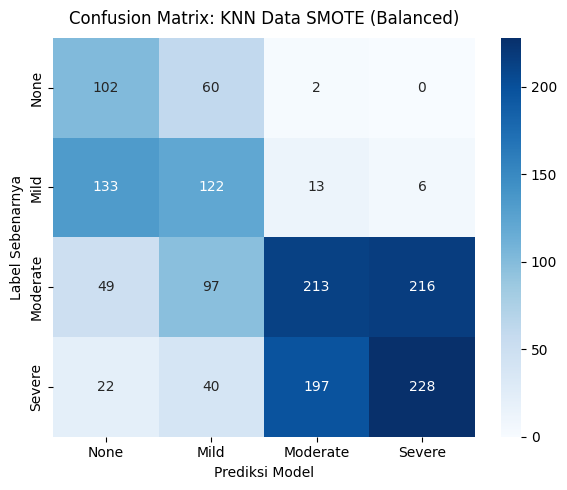

In [ ]:
#MODEL KNN DATA SMOTE
knn_bal = KNeighborsClassifier(n_neighbors=k_optimal)
knn_bal.fit(X_train_bal_scaled, y_train_bal)
y_pred_knn_bal = knn_bal.predict(X_test_scaled)

print(f"Akurasi Keseluruhan: {accuracy_score(y_test, y_pred_knn_bal):.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_knn_bal, target_names=['None', 'Mild', 'Moderate', 'Severe']))
plot_confusion_matrix(y_test, y_pred_knn_bal, "Confusion Matrix: KNN Data SMOTE (Balanced)")

Parameter Terbaik (Data Asli): {'class_weight': 'balanced_subsample', 'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 300}
Akurasi Akhir Random Forest (Data Asli): 51.27%

Classification Report:
              precision    recall  f1-score   support

        None       0.51      0.98      0.67       164
        Mild       0.55      0.43      0.48       274
    Moderate       0.51      0.11      0.19       575
      Severe       0.50      0.87      0.64       487

    accuracy                           0.51      1500
   macro avg       0.52      0.60      0.49      1500
weighted avg       0.52      0.51      0.44      1500



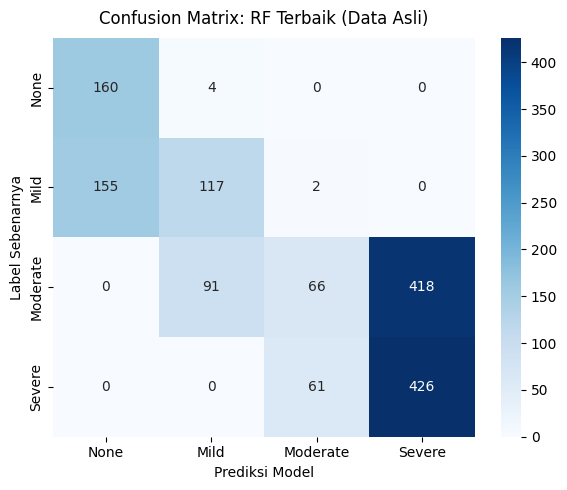

In [ ]:
#MODEL RANDOM FOREST DATA ASLI
param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced', 'balanced_subsample']
}

rf_base = RandomForestClassifier(random_state=42)
grid_rf_asli = GridSearchCV(estimator=rf_base, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf_asli.fit(X_train_imb, y_train_imb)

rf_best_asli = grid_rf_asli.best_estimator_
y_pred_rf_asli = rf_best_asli.predict(X_test)

print(f"Parameter Terbaik (Data Asli): {grid_rf_asli.best_params_}")
print(f"Akurasi Akhir Random Forest (Data Asli): {accuracy_score(y_test, y_pred_rf_asli):.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_rf_asli, target_names=['None', 'Mild', 'Moderate', 'Severe']))
plot_confusion_matrix(y_test, y_pred_rf_asli, "Confusion Matrix: RF Terbaik (Data Asli)")

Parameter Terbaik (Data SMOTE): {'class_weight': 'balanced', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Akurasi Akhir Random Forest (Data SMOTE): 49.67%

Classification Report:
              precision    recall  f1-score   support

        None       0.49      0.52      0.50       164
        Mild       0.51      0.58      0.54       274
    Moderate       0.49      0.34      0.40       575
      Severe       0.50      0.63      0.56       487

    accuracy                           0.50      1500
   macro avg       0.50      0.52      0.50      1500
weighted avg       0.50      0.50      0.49      1500



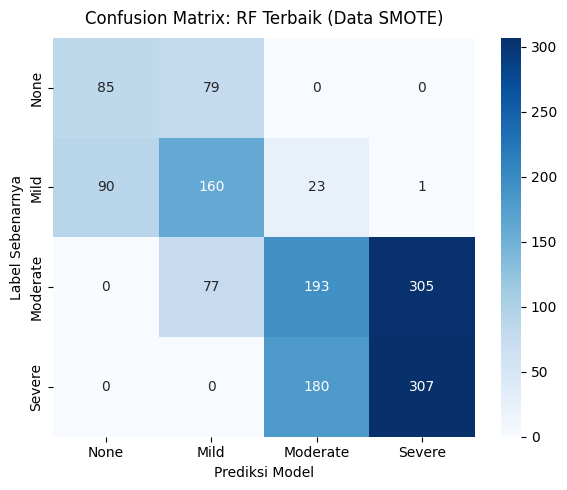

In [ ]:
#MODEL RANDOM FOREST DATA SMOTE
grid_rf_smote = GridSearchCV(estimator=rf_base, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf_smote.fit(X_train_bal, y_train_bal)

rf_best_smote = grid_rf_smote.best_estimator_
y_pred_rf_smote = rf_best_smote.predict(X_test)

print(f"Parameter Terbaik (Data SMOTE): {grid_rf_smote.best_params_}")
print(f"Akurasi Akhir Random Forest (Data SMOTE): {accuracy_score(y_test, y_pred_rf_smote):.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_rf_smote, target_names=['None', 'Mild', 'Moderate', 'Severe']))
plot_confusion_matrix(y_test, y_pred_rf_smote, "Confusion Matrix: RF Terbaik (Data SMOTE)")

FEATURE IMPORTANCE

/tmp/ipykernel_2790/771067364.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Fitur', data=data_importance, palette='viridis')


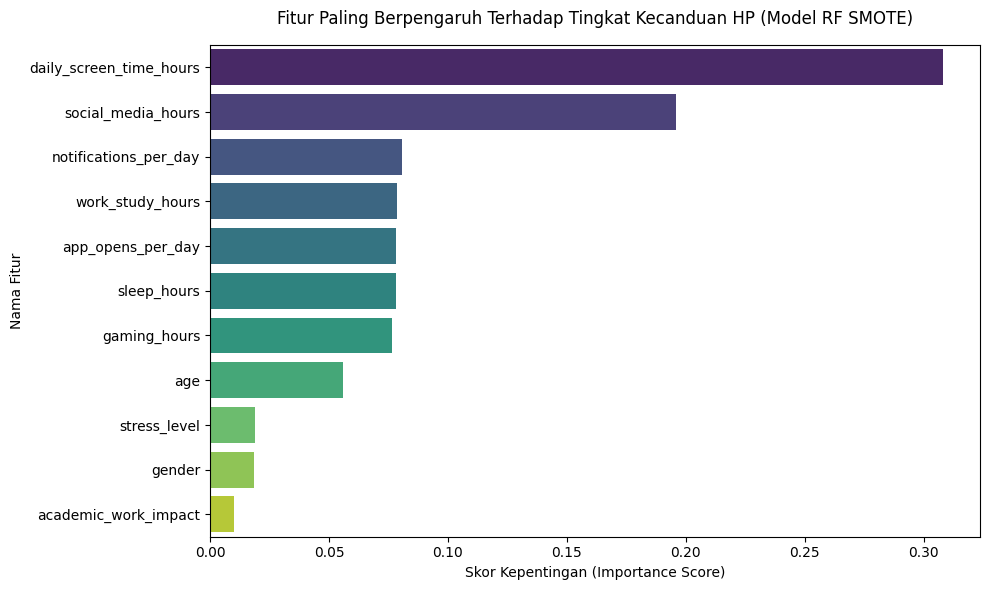

In [ ]:
#RANDOM FOREST
importances = rf_best_smote.feature_importances_
features = X.columns

data_importance = pd.DataFrame({
    'Fitur': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 3. Visualisasikan dalam bentuk Bar PlotHorizontal
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Fitur', data=data_importance, palette='viridis')
plt.title('Fitur Paling Berpengaruh Terhadap Tingkat Kecanduan HP (Model RF SMOTE)', fontsize=12, pad=15)
plt.xlabel('Skor Kepentingan (Importance Score)')
plt.ylabel('Nama Fitur')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2790/3569847405.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Fitur', data=data_knn_importance, palette='mako')


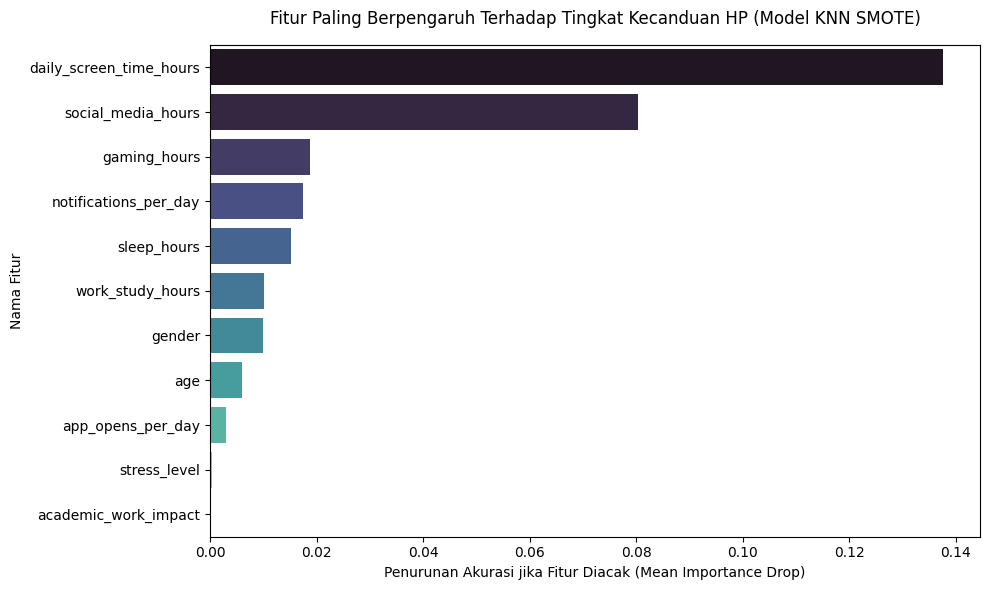

In [ ]:
#KNN
result = permutation_importance(knn_bal, X_test_scaled, y_test, n_repeats=10, random_state=42, n_jobs=-1)

data_knn_importance = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': result.importances_mean
}).sort_values(by='Importance', ascending=False)

# 3. Visualisasikan dalam bentuk Bar Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Fitur', data=data_knn_importance, palette='mako')
plt.title('Fitur Paling Berpengaruh Terhadap Tingkat Kecanduan HP (Model KNN SMOTE)', fontsize=12, pad=15)
plt.xlabel('Penurunan Akurasi jika Fitur Diacak (Mean Importance Drop)')
plt.ylabel('Nama Fitur')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2790/4294944136.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


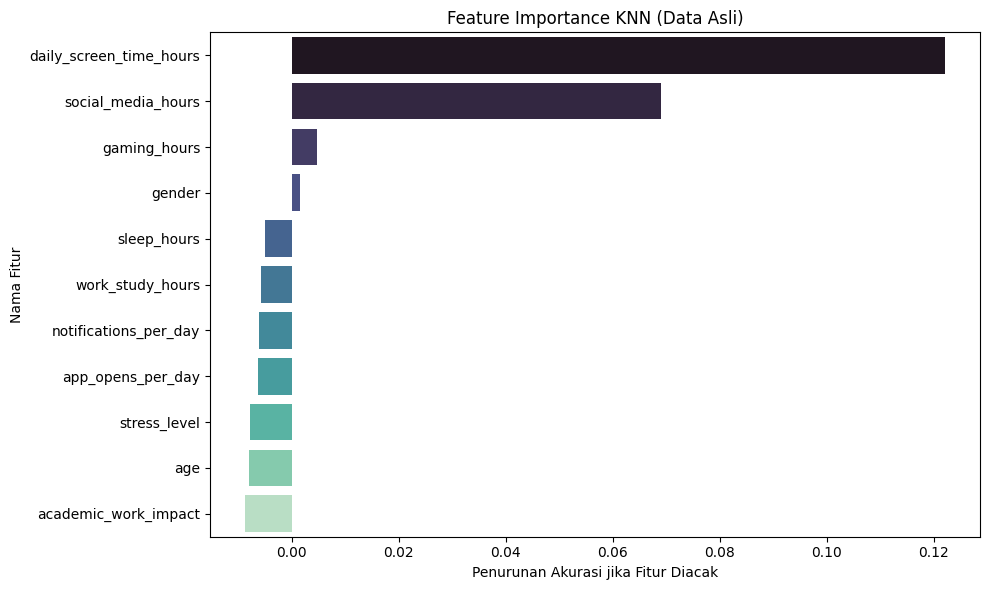

In [ ]:
from sklearn.inspection import permutation_importance

X = data_hp_usage_clean.drop(columns=['addiction_level'])
y = data_hp_usage_clean['addiction_level']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn_model = KNeighborsClassifier(n_neighbors=15)

knn_model.fit(X_train_scaled, y_train)

knn_result = permutation_importance(
    knn_model,
    X_test_scaled,
    y_test,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

knn_importance = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': knn_result.importances_mean
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10,6))

sns.barplot(
    data=knn_importance,
    x='Importance',
    y='Fitur',
    palette='mako'
)

plt.title('Feature Importance KNN (Data Asli)')
plt.xlabel('Penurunan Akurasi jika Fitur Diacak')
plt.ylabel('Nama Fitur')

plt.tight_layout()
plt.show()

/tmp/ipykernel_2790/2285888918.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


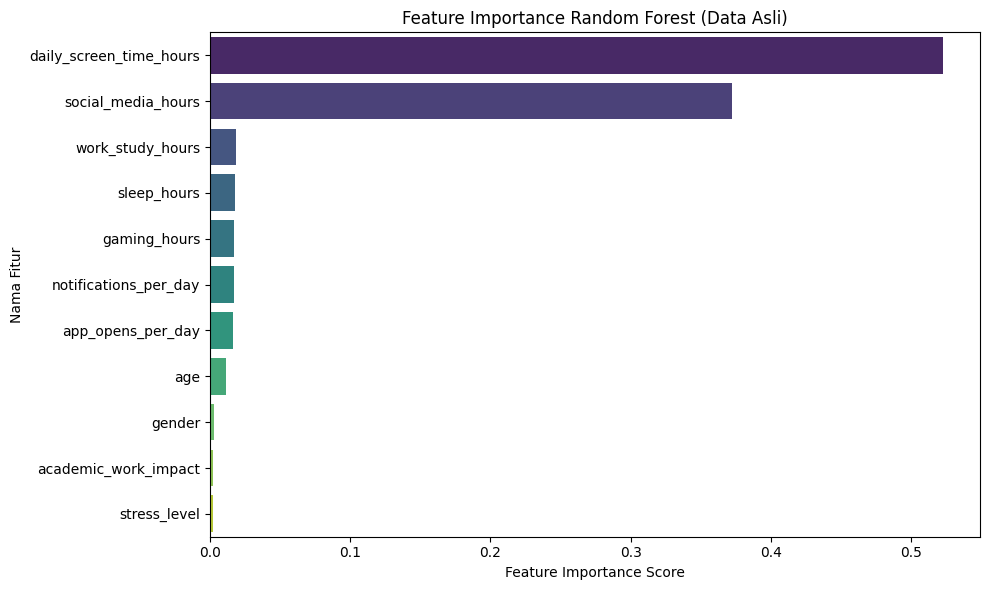

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_split=10,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_importance = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10,6))

sns.barplot(
    data=rf_importance,
    x='Importance',
    y='Fitur',
    palette='viridis'
)

plt.title('Feature Importance Random Forest (Data Asli)')
plt.xlabel('Feature Importance Score')
plt.ylabel('Nama Fitur')

plt.tight_layout()
plt.show()